# 06 · Slang ratio

**Does the share of words flagged as slang differ between winning and comparison openings?** Compare two ways to score the same minimally cleaned text.

| Method | Word-labeling rule |
| --- | --- |
| Curated dictionary | Look for the fixed internet abbreviations and colloquial expressions listed in the [project dictionary](slang_dictionary.tsv). Match case-insensitively at word boundaries. Count both words when a match spans multiple word tokens. |
| Contextual model | Fit logistic regression on externally annotated words using spelling, case, adjacent tokens, and their combinations. Predict a slang label at probability 0.5 or higher. |

For both methods, divide flagged word occurrences by total shared word-token occurrences. Repetitions count. The dictionary's scope includes shorthand such as “imo” and colloquial forms such as “gonna”. The model follows its annotation corpus, so the definitions can differ. The external corpus includes slang from different periods and sources, with examples of newer slang that may be uncommon in the CMV sample. A content word flagged by one method can be literal in context. [External annotation data](https://github.com/Sohaila-Abdulsattar/Slang-Detection-and-Identification/blob/main/datasets/bio_tagged_dataset_final.csv)

The [standalone script](analyze_slang_ratio.py) scores both methods locally and saves timestamped results. To regenerate, download the external CSV to `project/data/raw/slang/bio_tagged_dataset_final.csv` or pass its path with `--bio-csv`. The report records the CSV and dictionary hashes.

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/slang-ratio"
SCRIPT = REPO / "project/notebooks/linguistic-features/informality/analyze_slang_ratio.py"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "paired_scores.parquet")
openings = pd.read_parquet(report_path.parent / "opening_scores.parquet")
print(f"{len(pairs):,} complete pairs · {len(openings):,} unique openings · {report['discussions']:,} discussions")

3,451 complete pairs · 6,581 unique openings · 2,507 discussions


## Model and dictionary coverage

Evaluate the model's word labels on a seeded 20% split of distinct annotated sentences, then refit on the whole external dataset for CMV scoring. This diagnostic measures performance on the external annotations. We would need human slang labels on CMV openings to measure detection accuracy there.

Compare how often the two methods flag text in CMV. Token overlap is the number of word positions flagged by both divided by the number flagged by either.

In [2]:
labels = {"dictionary": "Curated dictionary", "contextual": "Contextual model"}
external = report["external_validation"]
display(pd.Series(external, name="External annotation diagnostic").round(4).to_frame())

coverage = pd.DataFrame([{
    "Method": labels[metric["method"]],
    "Openings with hits": metric["openings_with_hits"],
    "Openings with hits (%)": 100 * metric["openings_with_hits"] / len(openings),
    "Flagged tokens (%)": 100 * metric["token_share"],
} for metric in report["metrics"]]).set_index("Method")
display(coverage.round(3))
both = openings["both_tokens"].sum()
either = openings["dictionary_tokens"].sum() + openings["contextual_tokens"].sum() - both
if either:
    print(f"Word positions flagged by both methods: {both:,} of {either:,} flagged by either ({both/either:.1%}).")

,External annotation diagnostic
source_rows,4035.0000
malformed_rows,3.0000
conflicting_sentences,2.0000
usable_distinct_sentences,4002.0000
validation_sentences,801.0000
validation_tokens,6747.0000
validation_prevalence,0.1347
validation_average_precision,0.8326
validation_precision,0.8461
validation_recall,0.6953


,Openings with hits,Openings with hits (%),Flagged tokens (%)
Method,,,
Curated dictionary,539,8.190,0.053
Contextual model,5396,81.994,1.611


Word positions flagged by both methods: 542 of 25,168 flagged by either (2.2%).


## Review flagged words

Inspect a seeded sample from openings where both methods flagged the same word position, only the model flagged words, or only the dictionary flagged words. Brackets mark the first flagged word in each method's excerpt. Openings where both methods flag words can also include disagreements. The sample can surface ambiguous terms and domain errors without estimating error rates. Use the most frequent flags to check whether the tagger is responding to ordinary vocabulary in CMV.

In [3]:
from collections import Counter

dictionary_hits = openings["dictionary_tokens"].gt(0)
contextual_hits = openings["contextual_tokens"].gt(0)
review_groups = {
    "Overlap": openings["both_tokens"].gt(0),
    "Model only": contextual_hits & ~dictionary_hits,
    "Dictionary only": dictionary_hits & ~contextual_hits,
}
samples = {
    label: openings.loc[mask].sample(n=min(4, int(mask.sum())), random_state=42)
    for label, mask in review_groups.items()
}
review = pd.concat(samples)
display(review[["dictionary_context", "contextual_context"]])

top_terms = {}
for method, label in labels.items():
    terms = Counter(word for matches in openings[f"{method}_matches"] for word in matches)
    top_terms[label] = pd.Series(dict(terms.most_common(12)), name="Occurrences")
display(pd.concat(top_terms).to_frame())

dictionary_context                                                                                                        contextual_context
                comment_id                                                                                                                                                                                                                                              
Overlap         t1_ck7aczu  submit I would not be justified in doing such a thing. 【TL】;DR: As a general moral principle, you aren't justified  uppose it was plausible that you might actually end up 【knocking】 another child in the pond, resulting in its death, dur
                t1_cgy0c2d   ing and supporting her choice you could help too. And 【BTW】 how would you feel about your opinion if suddenly she         ing and supporting her choice you could help too. And 【BTW】 how would you feel about your opinion if suddenly she
                t1_chy0rmg   a voice controlled head up display has some potential 【IMO】. let me give an example: As a glider pilot, i could I    er than it being new shiny and having a nice big touch 【screen】. See the parallels? Now for most people the iPad might
                t1_ckzkrjm  f diminishing returns, I would have agreed entirely. 【TLDR】: Some things can only get so many quality upgrades bef       I disagree, on the grounds that it is stated as a 【universal】 truth when it can not be. Some things only have a cer
Model only      t1_cbc693d                                                                                                                                                                So you're saying 【IMDB】 does judge movies in the context of their time, and th
                t1_cn620d0                                                                                                                                        You remember that old phrase from Forest 【Gump】, "a man only needs so much money, the rest is just for
                t1_c9vp3i5                                                                                                                             massive supercomputer at some lab or private company (【IBM】). Once the amount of calculations can be achieved, an
                t1_cbn9wrg                                                                                                                        some extent, I disagree with this. Given that women in 【pornos】 frequently fake orgasms for the camera, this leads men
Dictionary only t1_cgqk4rp                                                         【tl】;dr: The theory not only does not hold up under scrutin                                                                                                                          
                t1_c9zjpoy   many state, it's not supposed to take over one's life. 【tl】;dr It's the culture in some Islamic states, not Islam                                                                                                                          
                t1_chsxgnl   w that's not relevant, but I really want to say that. 【tl】;dr someone for equality is egalitarian, a women's righ                                                                                                                          
                t1_clhgd1b                                                  You 【gotta】 ask yourself what makes you think sex is something int

Occurrences
Curated dictionary tl                189
                   dr                189
                   imo                58
                   gonna              55
                   kinda              51
                   tldr               31
                   btw                30
                   gotta              21
                   iirc               20
                   lol                20
                   ain't              17
                   nope               16
Contextual model   us                786
                   a                 445
                   market            326
                   short             322
                   shit              278
                   kids              269
                   universe          266
                   children          238
                   high              220
                   b                 213
                   kid               190
                   u                 182

## Paired association and standalone prediction

For each method, report the percentage of unequal-score pairs in which the opening with the higher ratio won. Report ties and 95% OP-discussion bootstrap intervals. Check pairs within 50 opening words separately.

Predict whether randomized side A wins using one signed A-minus-B ratio difference per model. The models use the same complete training pairs, three OP-discussion-grouped folds, and fold-specific standardization. The CMV held-out split is reserved.

In [4]:
rows = []
for metric in report["metrics"]:
    for subset, key in (("All pairs", "winner_higher"), ("Within 50 words", "within_50_words")):
        statistics = metric[key]
        low, high = statistics["ci_95"]
        rate = statistics["winner_higher_rate"]
        rows.append({
            "Method": labels[metric["method"]], "Subset": subset,
            "Pairs": statistics["pairs"], "Ties": statistics["ties"],
            "Winner higher (%)": 100 * rate if rate is not None else np.nan,
            "95% CI lower (%)": 100 * low if low is not None else np.nan,
            "95% CI upper (%)": 100 * high if high is not None else np.nan,
        })
association = pd.DataFrame(rows).set_index(["Method", "Subset"])
display(association.round(2))

prediction = pd.DataFrame([{
    "Method": labels[metric["method"]], "ROC-AUC": metric["roc_auc"],
    "Average precision": metric["average_precision"], "A-wins prevalence": metric["a_win_prevalence"],
} for metric in report["metrics"]]).set_index("Method")
display(prediction.round(4))

Pairs  Ties  Winner higher (%)  95% CI lower (%)  95% CI upper (%)
Method             Subset                                                                             
Curated dictionary All pairs         3451  2931              55.00             50.74             59.46
                   Within 50 words   1144  1032              50.89             41.59             60.18
Contextual model   All pairs         3451   181              52.14             50.22             53.87
                   Within 50 words   1144   104              49.04             45.80             52.29

,ROC-AUC,Average precision,A-wins prevalence
Method,,,
Curated dictionary,0.4806,0.4842,0.4967
Contextual model,0.5273,0.5133,0.4967


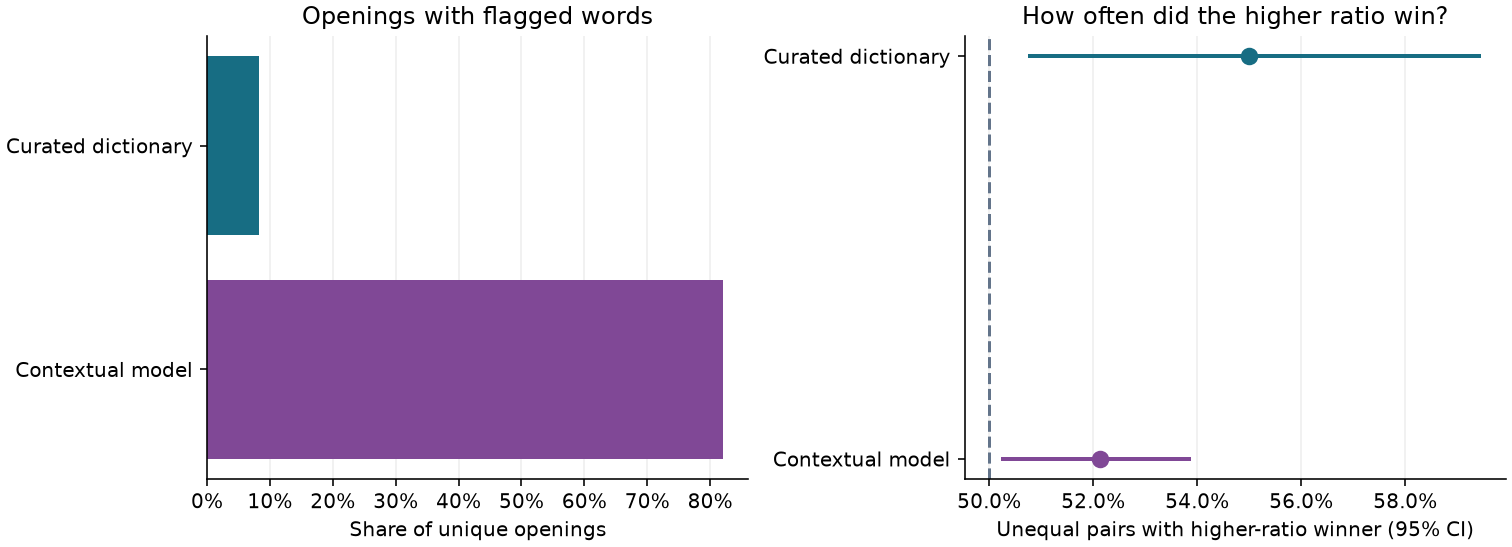

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, (coverage_plot, winner_plot) = plt.subplots(1, 2, figsize=(10.5, 3.8), layout="constrained")
colors = ["#176d83", "#804896"]
coverage_plot.barh(coverage.index, coverage["Openings with hits (%)"], color=colors)
coverage_plot.invert_yaxis()
coverage_plot.set(title="Openings with flagged words", xlabel="Share of unique openings")
coverage_plot.xaxis.set_major_formatter(PercentFormatter(100))

winner_plot.axvline(50, linestyle="--", color="#63748a")
for position, (label, color) in enumerate(zip(coverage.index, colors)):
    row = association.loc[(label, "All pairs")]
    winner_plot.hlines(position, row["95% CI lower (%)"], row["95% CI upper (%)"], color=color, lw=2)
    winner_plot.scatter(row["Winner higher (%)"], position, color=color, s=60, zorder=3)
winner_plot.set_yticks(range(len(coverage)), coverage.index)
winner_plot.invert_yaxis()
winner_plot.set(title="How often did the higher ratio win?", xlabel="Unequal pairs with higher-ratio winner (95% CI)")
winner_plot.xaxis.set_major_formatter(PercentFormatter(100))
for ax in (coverage_plot, winner_plot):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.22)
    ax.set_axisbelow(True)
plt.show()

## Interpretation

The curated dictionary is sparse in these openings, so its winner-higher estimate summarizes a small fraction of pairs. The contextual model flags many more words, including ordinary abbreviations and vocabulary in the review examples. Its external validation score does not establish accuracy on CMV. Both standalone ROC-AUC values are close to 0.5. In the subset within 50 opening words, both winner-higher intervals include 50%.